# 10 · Capstone: Post-Training a Diffusion Transformer, Diffusion Language Models, and the Modern Landscape

## Overview

The series so far, in one line each:

| Notebook | Idea | What it fixed | What it left open |
|---|---|---|---|
| 01 | Pretraining | The model knows things | Doesn't answer when asked |
| 02 | SFT + LoRA | Follows the format | Copies its demonstrators' mistakes; forgets |
| 03 | Reward model + PPO | Learns from comparisons | Reward hacking; heavy machinery |
| 04 | DPO family | One supervised loss | Offline: only re-weights its data |
| 05 | GRPO / RLVR | Verifiable rewards, no critic | Sharpens; needs a capable start |
| 06 | Diffusion | A different way to generate | Matches data, not goals; slow |
| 07 | Diffusion post-training | Reward-aligned denoisers | Hacking again (blobs, fooled judges) |
| 08 | Distillation | 1-4 step sampling | Small MLP denoisers |
| 09 | DiT + flow matching | Tokens, adaLN, text conditioning | Failed an unseen composition ("bold seven") |
| **10** | **Post-training the DiT; diffusion LMs** | **Both threads in one model family** | → today's research frontier |

Notebook 09 left a concrete failure: asked for a **"bold seven"**, a combination it never saw, the text-conditioned
DiT drew bold *ones* and *sixes*. Compositional prompts like this are what text-to-image benchmarks such as GenEval
test, and Flow-GRPO ([Liu et al., 2025](https://arxiv.org/abs/2505.05470)) improved exactly that kind of score with online RL. Part 1 does the same here.
Part 2 turns the comparison around: a **diffusion model that generates text**, post-trained with GRPO as in d1 ([Zhao et al., 2025](https://arxiv.org/abs/2504.12216)).
Part 3 maps every idea in the series onto real systems.

## Learning objectives

1. Convert a flow model's ODE sampler into an SDE with the same marginals, and use it to run GRPO on a DiT (Flow-GRPO).
2. Show that RL can fix a compositional failure only when the training distribution and the reward give it something to climb, and measure what it costs elsewhere.
3. Build a masked diffusion language model, explain why parallel decoding fails on multimodal data, and post-train it with GRPO.
4. Place InstructGPT, Llama, Tülu 3, DeepSeek-R1, SD3, FLUX, LLaDA and the other systems cited in this series on the map built here.

**Runtime:** about 15 minutes on a laptop CPU.

In [1]:
import sys, time, copy, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
sys.path.insert(0, ".")
from ptlib import tasks, images, metrics, set_seed, RESULTS_DIR
from ptlib import diffusion as dfx, dit, mdlm
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
judge, knn = images.get_judge(), images.PixelKNN()
text_dit = dit.get_text_dit()                         # notebook 09's caption-conditioned DiT
print(f"text-conditioned DiT: {sum(p.numel() for p in text_dit.parameters()):,} parameters")

text-conditioned DiT: 2,449,028 parameters


# Part 1 · Flow-GRPO on a diffusion transformer

## 1. From an ODE to an SDE

GRPO (notebook 05) needs a **stochastic** policy with tractable log-probabilities. A flow model samples with a
deterministic ODE, $dx/ds = v_\theta(x, s)$, which has no randomness to reinforce. Flow-GRPO's first step is to replace it
with an SDE that has the **same marginal distributions** at every $s$ but injects noise. For our interpolation
$x_s = (1-s)\,x_0 + s\,z$, the score of the marginal is $\nabla\log p_s(x) = -\big(x + (1-s)\,v\big)/s$. Adding $\tfrac{\sigma^2}{2}\nabla\log p_s$
to the drift and $\sigma\,dW$ noise leaves the marginals unchanged. Stepping from $s$ to $s - \Delta$:
$$x_{s-\Delta} = x_s - v_\theta\,\Delta - \frac{\sigma_s^2}{2s}\big(x_s + (1-s)\,v_\theta\big)\Delta + \sigma_s\sqrt{\Delta}\,\varepsilon, \qquad \sigma_s = a\sqrt{\tfrac{s}{1-s}}.$$

Each step is a Gaussian with a mean that depends on $\theta$, exactly as in DDPO (notebook 07). GRPO then runs unchanged.
For each prompt, sample $G$ images, score them, normalise rewards within the group, and take clipped policy-gradient
steps on every transition, with a KL penalty to the starting model.

In [2]:
import inspect
src = inspect.getsource(dfx.flow_sde_step_mean); print(src[src.index("    n = len(x)"):])
# the SDE sampler should produce the same distribution as the ODE sampler
caps = dit.encode_captions(["bold three"] * 300)
set_seed(0); ode = dfx.sample_flow(text_dit, caps, 20)
set_seed(0); sde, _ = dfx.flow_sde_sample_with_logprob(text_dit, caps, steps=20)
print(f"'bold three' via ODE: ink {dfx.ink(ode).mean():.3f}, kNN acc {knn.accuracy(ode, torch.full((300,), 3)):.3f}")
print(f"'bold three' via SDE: ink {dfx.ink(sde).mean():.3f}, kNN acc {knn.accuracy(sde, torch.full((300,), 3)):.3f}")

    n = len(x)
    v = guided(model, x, torch.full((n,), s * (T - 1)), c, w)
    sig = a * math.sqrt(min(s, 0.95) / (1 - min(s, 0.95)))
    mean = x - v * ds - (sig ** 2) / (2 * s) * (x + (1 - s) * v) * ds
    return mean, torch.full((n, 1), sig * math.sqrt(ds))

'bold three' via ODE: ink 0.695, kNN acc 0.773
'bold three' via SDE: ink 0.693, kNN acc 0.753


## 2. A (nearly) verifiable reward

Following RLVR (notebook 05), the reward is a rule: the image must be **bold** (ink ≥ 0.45) and must be the
**requested digit**. We use the judge's probability for that digit rather than a 0/1 decision, so the reward is dense.
Notebook 05 showed that a binary reward gives no signal when no sample succeeds, and "bold seven" starts close to zero.
$$r(x, c) = p_\text{judge}(\text{digit}(c) \mid x)\cdot \mathbb{1}[\text{ink}(x) \ge 0.45].$$

Notebook 07 showed that a judge inside the reward can be fooled, so the **kNN classifier stays held out** and is the
number we trust.

In [3]:
bold_prompts = dit.encode_captions(["bold " + w for w in dit.WORDS])
DIGIT = {tuple(bold_prompts[i].tolist()): i for i in range(10)}
digits_of = lambda c: torch.tensor([DIGIT[tuple(r.tolist())] for r in c])

def reward(x, c):
    d = digits_of(c)
    return F.softmax(judge(x), -1)[torch.arange(len(d)), d] * (dfx.ink(x) >= 0.45).float()

@torch.no_grad()
def evaluate(m, n_seven=150, n_other=30):
    out = {}
    for name, idx, n in [("bold seven", [7], n_seven), ("other bold digits", [0, 1, 2, 3, 4, 5, 6, 8, 9], n_other)]:
        c = bold_prompts[idx].repeat_interleave(n, 0); d = digits_of(c)
        set_seed(0); s = dfx.sample_flow(m, c, 20)
        out[f"{name}: kNN acc"] = knn.accuracy(s, d)
        out[f"{name}: judge acc"] = (judge(s).argmax(1) == d).float().mean().item()
        out[f"{name}: ink"] = dfx.ink(s).mean().item()
    return out

before = evaluate(text_dit)
print({k: round(v, 3) for k, v in before.items()})
set_seed(0); s7 = dfx.sample_flow(text_dit, bold_prompts[[7]].repeat(400, 1), 20)
r7 = reward(s7, bold_prompts[[7]].repeat(400, 1))
print(f"'bold seven' samples from the starting model: reward > 0.5 for {(r7 > 0.5).float().mean():.1%}; kNN reads them as",
      np.bincount(knn.clf.predict(s7.numpy()), minlength=10))

{'bold seven: kNN acc': 0.007, 'bold seven: judge acc': 0.013, 'bold seven: ink': 0.624, 'other bold digits: kNN acc': 0.859, 'other bold digits: judge acc': 0.822, 'other bold digits: ink': 0.696}
'bold seven' samples from the starting model: reward > 0.5 for 0.2%; kNN reads them as [  9 294   2   3   1  13  44   3  28   3]


Note what the last line implies for the offline methods of notebooks 04 and 07. A Diffusion-DPO dataset built from
the starting model's samples would contain almost no good bold sevens, so it would have nothing to prefer. Only
**online** sampling, where the policy's improving samples feed back into training, can climb out.

## 3. Two Flow-GRPO runs

* **Uniform prompts.** Each iteration draws 8 of the 10 "bold" prompts at random, with $G = 8$ images each.
* **Targeted prompts.** Half of the prompt pool is "bold seven", the case that failed.

In [4]:
ref = copy.deepcopy(text_dit).eval().requires_grad_(False)
runs, hists = {}, {}
t0 = time.time()
runs["Flow-GRPO, uniform prompts"], hists["Flow-GRPO, uniform prompts"] = dfx.flow_grpo(
    copy.deepcopy(text_dit), ref, bold_prompts, reward, iters=60, lr=2e-5, log_every=20, eval_fn=evaluate)
print(f"{time.time() - t0:.0f}s")
targeted = torch.cat([bold_prompts[[7]].repeat(9, 1), bold_prompts[[0, 1, 2, 3, 4, 5, 6, 8, 9]]])
t0 = time.time()
runs["Flow-GRPO, targeted prompts"], hists["Flow-GRPO, targeted prompts"] = dfx.flow_grpo(
    copy.deepcopy(text_dit), ref, targeted, reward, iters=80, lr=5e-5, log_every=20, eval_fn=evaluate)
print(f"{time.time() - t0:.0f}s")

{'iter': 20, 'reward': 0.559, 'groups_no_signal': 0.0, 'bold seven: kNN acc': 0.007, 'bold seven: judge acc': 0.013, 'bold seven: ink': 0.624, 'other bold digits: kNN acc': 0.878, 'other bold digits: judge acc': 0.874, 'other bold digits: ink': 0.692}
{'iter': 40, 'reward': 0.85, 'groups_no_signal': 0.0, 'bold seven: kNN acc': 0.007, 'bold seven: judge acc': 0.013, 'bold seven: ink': 0.621, 'other bold digits: kNN acc': 0.9, 'other bold digits: judge acc': 0.937, 'other bold digits: ink': 0.689}
{'iter': 60, 'reward': 0.882, 'groups_no_signal': 0.0, 'bold seven: kNN acc': 0.0, 'bold seven: judge acc': 0.013, 'bold seven: ink': 0.619, 'other bold digits: kNN acc': 0.944, 'other bold digits: judge acc': 0.959, 'other bold digits: ink': 0.683}
87s
{'iter': 20, 'reward': 0.338, 'groups_no_signal': 0.0, 'bold seven: kNN acc': 0.133, 'bold seven: judge acc': 0.127, 'bold seven: ink': 0.64, 'other bold digits: kNN acc': 0.896, 'other bold digits: judge acc': 0.881, 'other bold digits: ink': 0

,bold seven: kNN acc,bold seven: judge acc,bold seven: ink,other bold digits: kNN acc,other bold digits: judge acc,other bold digits: ink
before (notebook 09),0.007,0.013,0.624,0.859,0.822,0.696
"Flow-GRPO, uniform prompts",0.000,0.013,0.619,0.944,0.959,0.683
"Flow-GRPO, targeted prompts",0.900,0.987,0.643,0.967,0.963,0.672


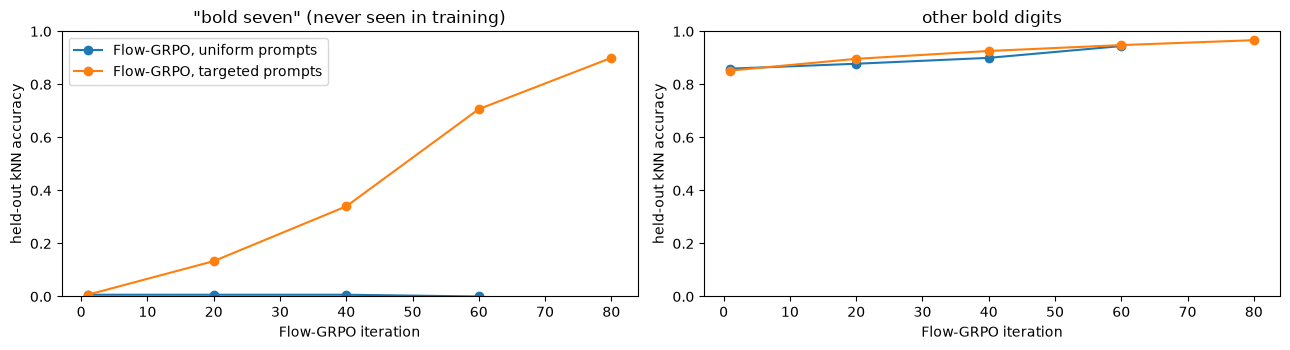

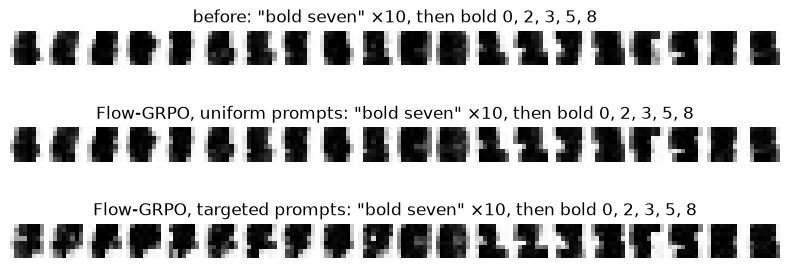

In [5]:
table = pd.DataFrame({"before (notebook 09)": before, **{k: evaluate(m) for k, m in runs.items()}}).T
display(table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for name, h in hists.items():
    h = pd.DataFrame(h).dropna()
    axes[0].plot(h["iter"], h["bold seven: kNN acc"], "o-", label=name)
    axes[1].plot(h["iter"], h["other bold digits: kNN acc"], "o-", label=name)
axes[0].set_title('"bold seven" (never seen in training)'); axes[1].set_title("other bold digits")
for ax in axes: ax.set_xlabel("Flow-GRPO iteration"); ax.set_ylabel("held-out kNN accuracy"); ax.set_ylim(0, 1)
axes[0].legend(); fig.tight_layout(); plt.show()
fig, axes = plt.subplots(3, 1, figsize=(8, 3.3))
for ax, (name, m) in zip(axes, [("before", text_dit), *runs.items()]):
    set_seed(1); images.show_grid(dfx.sample_flow(m, bold_prompts[[7, 7, 7, 7, 7, 0, 2, 3, 5, 8]].repeat_interleave(2, 0), 20), nrow=20, ax=ax,
                                  title=f'{name}: "bold seven" ×10, then bold 0, 2, 3, 5, 8')
fig.tight_layout(); plt.show()

**Reading Part 1.** Use the table and curves; one seed per run.

* **Uniform prompts** improve the bold digits the model could already draw. "Bold seven" barely moves, because it is one prompt in ten and its groups start with almost no reward to compare. This is notebook 05's lesson again: RL sharpens what the policy can already produce.
* **Targeted prompts** change that. With "bold seven" in half the groups, the small differences in judge probability between samples are enough for group-normalised advantages to climb. The held-out kNN, never part of the reward, agrees that the model now draws bold sevens. The other prompts stay in the pool, and they do not degrade.
* The ingredients are the ones the series built: a stochastic sampler with Gaussian transitions (07), group-relative advantages and a KL anchor (05), a dense, rule-based reward (05), a held-out evaluator (03, 07) and **prompt selection** (DAPO's dynamic sampling, [Yu et al., 2025](https://arxiv.org/abs/2503.14476)). DanceGRPO ([Xue et al., 2025](https://arxiv.org/abs/2505.07818)) applies the same recipe to video and text-to-image models at scale.

# Part 2 · A diffusion model that writes text

## 4. Masked diffusion language models

Discrete diffusion ([Austin et al., 2021](https://arxiv.org/abs/2107.03006)) replaces Gaussian noise with token corruption. The simplest and most effective
form is **masking** ([Sahoo et al., 2024](https://arxiv.org/abs/2406.07524), [Shi et al., 2024](https://arxiv.org/abs/2406.04329), [Lou et al., 2023](https://arxiv.org/abs/2310.16834)). At time $t$, each answer token is independently replaced by
`[MASK]` with probability $t$, and a **bidirectional** transformer learns to predict the originals. The training loss
$$\mathcal{L} = \mathbb{E}_t\,\frac{1}{t}\sum_{i\,\in\,\text{masked}} -\log p_\theta(y_i \mid \tilde y, x)$$
is an ELBO, the discrete counterpart of notebook 06's denoising loss. LLaDA ([Nie et al., 2025](https://arxiv.org/abs/2502.09992)) scaled this to an 8B-parameter
language model competitive with autoregressive LLMs of similar size. Generation starts from an all-masked answer and
**unmasks** tokens over several steps, most confident first, in any order.

We train one on notebook 02's setting: arithmetic answers written by careful and **sloppy** annotators, with 18% of
answers wrong.

masked diffusion LM: 809,266 parameters, answer = 6 slots
step  1000  loss 0.9400  (744s)
step  2000  loss 0.2798  (12169s)
step  3000  loss 0.2054  (28956s)
trained in 28956s
{'3-digit, 6 steps, sampled': 0.267, '3-digit, 1 step, sampled': 0.227, '2-digit, 6 steps, sampled': 0.897, '2-digit, 1 step, sampled': 0.767, '3-digit, 6 steps, greedy': 0.36}


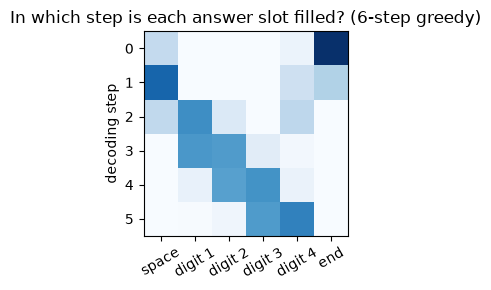

["' 1417\\n'", "' 426\\n\\n'", "' 1051\\n'", "' 1090\\n'"]


In [6]:
md_model = mdlm.MaskedDiffusionLM()
print(f"masked diffusion LM: {sum(p.numel() for p in md_model.parameters()):,} parameters, answer = {mdlm.A_LEN} slots")
t0 = time.time()
mdlm.train(md_model, mdlm.training_data(n3=2000), steps=3000, noise=0.18, log_every=1000)
print(f"trained in {time.time() - t0:.0f}s")
E3, E2 = tasks.TEST_3D[:300], tasks.TEST_2D[:300]
def lm_eval(m):
    return {f"{d}-digit, {k} step{'s' if k > 1 else ''}, sampled": mdlm.accuracy(m, E, temperature=1.0, steps=k)
            for d, E in [(3, E3), (2, E2)] for k in [6, 1]} | {"3-digit, 6 steps, greedy": mdlm.accuracy(m, E3, steps=6)}
lm_before = lm_eval(md_model)
print({k: round(v, 3) for k, v in lm_before.items()})
texts, order = mdlm.generate(md_model, [mdlm.prompt_of(a, b) for a, b in E3[:200]], return_order=True)
fig, ax = plt.subplots(figsize=(6, 3))
ax.imshow(np.stack([np.bincount(order[:, j].numpy(), minlength=6) for j in range(mdlm.A_LEN)]).T / 200, cmap="Blues")
ax.set_xticks(range(mdlm.A_LEN)); ax.set_xticklabels(["space", "digit 1", "digit 2", "digit 3", "digit 4", "end"], rotation=30)
ax.set_ylabel("decoding step"); ax.set_title("In which step is each answer slot filled? (6-step greedy)"); fig.tight_layout(); plt.show()
print([repr(t) for t in texts[:4]])

Two observations.

* **Any-order generation.** The heat map shows the order in which the model commits to each answer slot, which an autoregressive model fixes at left to right. Where it is not left to right, the model has chosen for itself which digit is easiest to commit to first.
* **Parallel decoding has a price.** Decoding all six slots in **one** step is six times cheaper, but accuracy drops, more than with notebook 02's autoregressive model. With noisy data the answer distribution is **multimodal** (right answer, or one of several plausible wrong ones). Decoding the slots *independently* can mix digits from different modes, producing answers no annotator ever wrote. On clean data, where each prompt has one answer, one-step decoding is nearly lossless. Try it in Challenge Problem 1.

## 5. GRPO for a diffusion LM (d1)

To run GRPO we need $\log\pi_\theta(y \mid x)$. For iterative unmasking this is intractable, so d1 ([Zhao et al., 2025](https://arxiv.org/abs/2504.12216)) uses a one-pass,
mean-field estimate: mask the whole answer and add up the per-slot log-probabilities of the sampled tokens. For
**one-step** decoding this estimate is not an approximation: it is exactly the probability of the sample. So we
post-train the cheap one-step decoder directly, with the verifier as reward, exactly as in notebook 05.

In [7]:
src = inspect.getsource(mdlm.answer_logprob); print(src[src.index("    ids = encode_batch"):])
md_ref = copy.deepcopy(md_model).eval().requires_grad_(False)
md_rl = copy.deepcopy(md_model)
t0 = time.time()
md_hist = mdlm.diffu_grpo(md_rl, md_ref, steps=150, decode_steps=1, lr=5e-5, log_every=50)
print(f"{time.time() - t0:.0f}s")
lm_after = lm_eval(md_rl)
lm_table = pd.DataFrame({"masked diffusion LM (noisy SFT)": lm_before, "+ GRPO on 1-step decoding": lm_after}).T
display(lm_table.round(3))

    ids = encode_batch(prompts)
    if p_mask_prompt > 0:
        pm = (torch.rand(len(prompts), P_LEN) < p_mask_prompt) & (ids[:, :P_LEN] != tasks.PAD_ID)
        ids[:, :P_LEN][pm] = MASK
    target = torch.tensor([tasks.encode(a) for a in answers])
    lp = F.log_softmax(model(ids).float(), -1)
    return torch.gather(lp, 2, target[..., None])[..., 0].sum(1)

iter   50  train reward 0.308  (772s)
iter  100  train reward 0.404  (783s)
iter  150  train reward 0.487  (1113s)
1113s


,"3-digit, 6 steps, sampled","3-digit, 1 step, sampled","2-digit, 6 steps, sampled","2-digit, 1 step, sampled","3-digit, 6 steps, greedy"
masked diffusion LM (noisy SFT),0.267,0.227,0.897,0.767,0.360
+ GRPO on 1-step decoding,0.350,0.517,0.900,0.847,0.417


**Reading Part 2.** The table is the result. GRPO with a verifier more than doubles the **one-step sampled** 3-digit
accuracy, the decoding mode it was trained on, and the gain partly transfers to six-step decoding and to greedy
decoding. Two caveats. First, this diffusion LM learned 3-digit addition only partially from noisy data: in development
runs with the same settings its starting accuracy was much higher, because the 3-digit skill appears abruptly during
training. On clean data the same model reaches near-perfect 3-digit accuracy (Challenge Problem 1). Second, in an earlier
run with a smaller starting gap, greedy accuracy dipped slightly while sampled accuracy rose. RL optimises what is
right *when sampled*, which need not be the single most likely answer. These are the same effects as notebook 05, in a model that generates by denoising rather than left to
right. At scale, d1 reports that this combination (a masked diffusion LM, SFT, then diffu-GRPO) improves LLaDA's
mathematical reasoning.

# Part 3 · The whole series

## 6. One scorecard

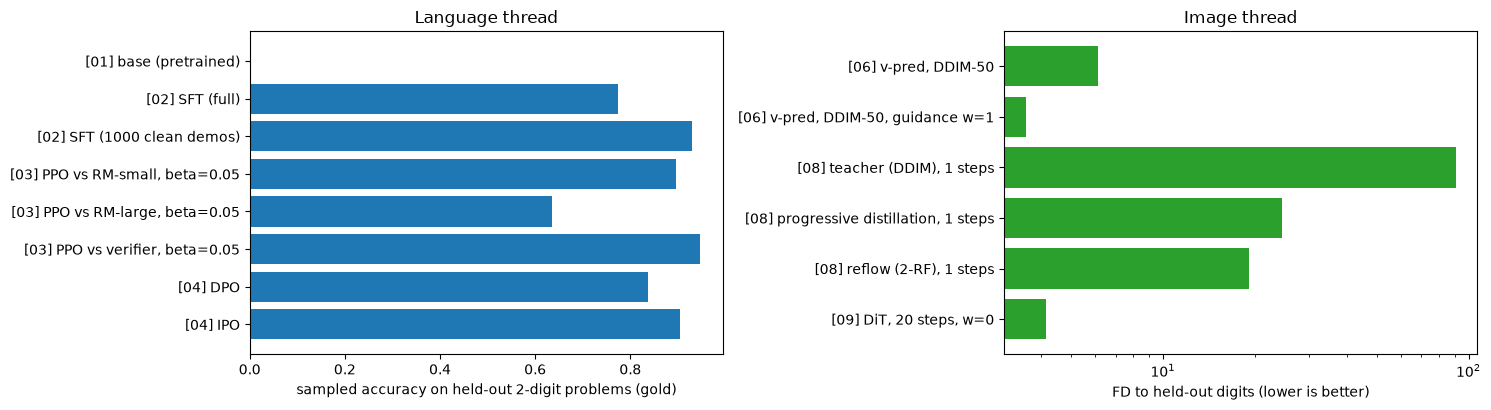

results/series_scorecard.csv: 61 rows from 10 notebooks


In [8]:
sc = metrics.load_scorecard()
lm_pick = [("01_pretraining", "base (pretrained)"), ("02_sft", "SFT (full)"), ("02_sft", "SFT (1000 clean demos)"),
           ("03_rlhf_ppo", "PPO vs RM-small, beta=0.05"), ("03_rlhf_ppo", "PPO vs RM-large, beta=0.05"), ("03_rlhf_ppo", "PPO vs verifier, beta=0.05"),
           ("04_dpo", "DPO"), ("04_dpo", "IPO")]
lm_rows = pd.concat([sc[(sc.notebook == n) & (sc.model == m)] for n, m in lm_pick])
img_pick = [("06_diffusion", "v-pred, DDIM-50"), ("06_diffusion", "v-pred, DDIM-50, guidance w=1"), ("08_distillation", "teacher (DDIM), 1 steps"),
            ("08_distillation", "progressive distillation, 1 steps"), ("08_distillation", "reflow (2-RF), 1 steps"), ("09_dit", "DiT, 20 steps, w=0")]
img_rows = pd.concat([sc[(sc.notebook == n) & (sc.model == m)] for n, m in img_pick])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
lab = lambda r: f"[{r.notebook[:2]}] {r.model}"
axes[0].barh([lab(r) for r in lm_rows.itertuples()][::-1], lm_rows.sampled_acc[::-1], color="tab:blue")
axes[0].set_xlabel("sampled accuracy on held-out 2-digit problems (gold)"); axes[0].set_title("Language thread")
axes[1].barh([lab(r) for r in img_rows.itertuples()][::-1], img_rows.fd[::-1], color="tab:green")
axes[1].set_xlabel("FD to held-out digits (lower is better)"); axes[1].set_xscale("log"); axes[1].set_title("Image thread")
fig.tight_layout(); plt.show()
cap_rows = [dict(model=k, family="image-text-dit", **v) for k, v in table.to_dict("index").items()] + \
           [dict(model=k, family="diffusion-lm", **v) for k, v in lm_table.to_dict("index").items()]
metrics.append_rows(cap_rows, "10_capstone")
series = metrics.load_scorecard()
series.to_csv(os.path.join(RESULTS_DIR, "series_scorecard.csv"), index=False)
print(f"results/series_scorecard.csv: {len(series)} rows from {series.notebook.nunique()} notebooks")

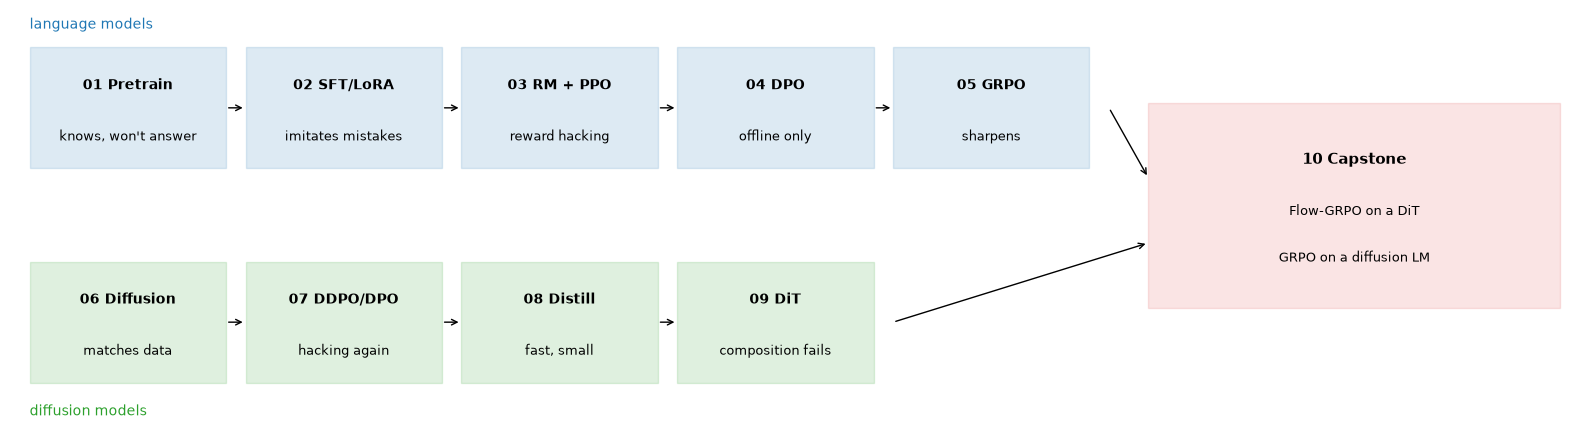

In [9]:
fig, ax = plt.subplots(figsize=(16, 4.4)); ax.set_xlim(0, 16); ax.set_ylim(0, 4.4); ax.axis("off")
lm_stages = [("01 Pretrain", "knows, won't answer"), ("02 SFT/LoRA", "imitates mistakes"), ("03 RM + PPO", "reward hacking"),
             ("04 DPO", "offline only"), ("05 GRPO", "sharpens")]
img_stages = [("06 Diffusion", "matches data"), ("07 DDPO/DPO", "hacking again"), ("08 Distill", "fast, small"), ("09 DiT", "composition fails")]
for i, (t, s) in enumerate(lm_stages):
    ax.add_patch(plt.Rectangle((0.2 + i * 2.2, 2.7), 2.0, 1.3, fc="tab:blue", alpha=0.15, ec="tab:blue"))
    ax.text(1.2 + i * 2.2, 3.55, t, ha="center", fontsize=10, weight="bold"); ax.text(1.2 + i * 2.2, 3.0, s, ha="center", fontsize=9)
for i, (t, s) in enumerate(img_stages):
    ax.add_patch(plt.Rectangle((0.2 + i * 2.2, 0.4), 2.0, 1.3, fc="tab:green", alpha=0.15, ec="tab:green"))
    ax.text(1.2 + i * 2.2, 1.25, t, ha="center", fontsize=10, weight="bold"); ax.text(1.2 + i * 2.2, 0.7, s, ha="center", fontsize=9)
for y in [3.35, 1.05]:
    for i in range(4 if y > 2 else 3):
        ax.annotate("", (0.2 + (i + 1) * 2.2, y), (0.2 + i * 2.2 + 2.0, y), arrowprops=dict(arrowstyle="->"))
ax.add_patch(plt.Rectangle((11.6, 1.2), 4.2, 2.2, fc="tab:red", alpha=0.12, ec="tab:red"))
ax.text(13.7, 2.75, "10 Capstone", ha="center", fontsize=11, weight="bold")
ax.text(13.7, 2.2, "Flow-GRPO on a DiT", ha="center", fontsize=9); ax.text(13.7, 1.7, "GRPO on a diffusion LM", ha="center", fontsize=9)
ax.annotate("", (11.6, 2.6), (11.2, 3.35), arrowprops=dict(arrowstyle="->")); ax.annotate("", (11.6, 1.9), (9.0, 1.05), arrowprops=dict(arrowstyle="->"))
ax.text(0.2, 4.2, "language models", color="tab:blue", fontsize=10); ax.text(0.2, 0.05, "diffusion models", color="tab:green", fontsize=10)
fig.tight_layout(); plt.show()

## 7. The modern landscape, mapped onto this series

| System | Post-training recipe (in this series' terms) | Ideas from |
|---|---|---|
| **InstructGPT** ([Ouyang et al., 2022](https://arxiv.org/abs/2203.02155)) | SFT → reward model → PPO with KL penalty (+ pretraining mix against forgetting) | NB02, NB03 |
| **Llama 2** ([Touvron et al., 2023](https://arxiv.org/abs/2307.09288)) | SFT → rejection-sampling fine-tuning → PPO, iterated with fresh preference data | NB02, NB03, NB05 (STaR) |
| **Llama 3** ([Grattafiori et al., 2024](https://arxiv.org/abs/2407.21783)) | SFT → rejection sampling → DPO, several rounds on on-policy data | NB04 (iterative DPO) |
| **Tülu 3** ([Lambert et al., 2024](https://arxiv.org/abs/2411.15124)) | SFT → DPO on on-policy preferences → RL with verifiable rewards | NB02, NB04, NB05 |
| **DeepSeek-R1** ([DeepSeek-AI et al., 2025](https://arxiv.org/abs/2501.12948)) | cold-start SFT → GRPO with rule-based rewards → rejection sampling → RL again | NB05 |
| **Stable Diffusion 3** ([Esser et al., 2024](https://arxiv.org/abs/2403.03206)) | MM-DiT with joint text–image attention, rectified flow, logit-normal timesteps | NB09 |
| **FLUX.1 Kontext** ([Labs et al., 2025](https://arxiv.org/abs/2506.15742)) | flow-matching DiT for in-context image generation and editing | NB09 |
| **Diffusion-DPO** ([Wallace et al., 2023](https://arxiv.org/abs/2311.12908)) | DPO with denoising errors in place of log-likelihoods | NB04, NB07 |
| **LCM / ADD / DMD** ([Luo et al., 2023](https://arxiv.org/abs/2310.04378), [Sauer et al., 2023](https://arxiv.org/abs/2311.17042), [Yin et al., 2023](https://arxiv.org/abs/2311.18828)) | consistency, adversarial and distribution-matching distillation to 1-4 steps | NB08 |
| **Flow-GRPO / DanceGRPO** ([Liu et al., 2025](https://arxiv.org/abs/2505.05470), [Xue et al., 2025](https://arxiv.org/abs/2505.07818)) | ODE→SDE + GRPO for flow models | NB05, NB07, NB10 |
| **LLaDA** ([Nie et al., 2025](https://arxiv.org/abs/2502.09992)) | masked diffusion LM pretrained and SFT'd at 8B scale | NB06, NB10 |
| **d1** ([Zhao et al., 2025](https://arxiv.org/abs/2504.12216)) | SFT + diffu-GRPO for masked diffusion LMs | NB05, NB10 |

Read top to bottom, the table shows the convergence this series built toward. Language models adopted RL with
verifiable rewards and group baselines. Image models adopted DPO and GRPO from language models. And diffusion
transformers are now used as language models too.

## Challenge Problem 1: Parallel decoding on clean data

Train a second masked diffusion LM with `noise=0.0` (same data, same 3,000 steps) and compare its one-step and six-step sampled accuracy.
Does the parallel-decoding gap close? Explain the answer in terms of how many modes the conditional answer distribution has.

In [10]:
# Start your code here

### Challenge Problem 1 Solution

In [11]:
clean_md = mdlm.MaskedDiffusionLM()
mdlm.train(clean_md, mdlm.training_data(n3=2000), steps=3000, noise=0.0, log_every=0)
for k in [6, 1]:
    print(f"clean data, {k} step(s): 3-digit sampled acc {mdlm.accuracy(clean_md, E3, temperature=1.0, steps=k):.3f}")
# With one correct answer per prompt, every slot's marginal is (nearly) a point mass, so decoding the slots independently
# loses nothing. Parallel decoding fails only when several different complete answers are plausible.

clean data, 6 step(s): 3-digit sampled acc 1.000
clean data, 1 step(s): 3-digit sampled acc 0.977


## Challenge Problem 2: Where would you take this next?

Pick one direction and sketch (in a few sentences, or in code) how you would implement it with the pieces from this series:

1. **Process rewards.** Give the 3-digit task a scratchpad (one line per column, with carries) and reward each correct line, not just the final answer ([Lightman et al., 2023](https://arxiv.org/abs/2305.20050)). Which notebook's code changes, and how would you stop the model from writing long, useless scratchpads?
2. **Reward models for images.** Replace the hand-written ink rule with a reward model trained on pairwise preferences over generated digits (notebook 03's Bradley–Terry loss on the judge's features). Then run Flow-GRPO against it and measure overoptimisation with the kNN.
3. **Distil the aligned DiT.** Apply notebook 08's reflow to the Flow-GRPO model and check whether "bold seven" survives at one step.

In [12]:
# Start your code here

### Challenge Problem 2 Solution

In [13]:
# A sketch for direction 3, using only functions from ptlib (about 1-2 minutes):
aligned = runs["Flow-GRPO, targeted prompts"]
set_seed(5)
c = bold_prompts[torch.randint(0, 10, (3000,))]; z = torch.randn(3000, 64)
x_hat = dfx.sample_flow(aligned, c, 20, x_T=z).clamp(-1, 1)
student, _ = dfx.train_flow(copy.deepcopy(aligned), x_hat, c, X0=z, steps=800, batch=128, lr=1e-4, p_uncond=0.0, log_every=0)
c7 = bold_prompts[[7]].repeat(150, 1); set_seed(0)
for name, m, n in [("aligned DiT, 20 steps", aligned, 20), ("aligned DiT, 1 step", aligned, 1), ("reflowed student, 1 step", student, 1)]:
    set_seed(0); s = dfx.sample_flow(m, c7, n)
    print(f"{name:26s} 'bold seven' kNN acc {knn.accuracy(s, torch.full((150,), 7)):.3f}, ink {dfx.ink(s).mean():.3f}")

aligned DiT, 20 steps      'bold seven' kNN acc 0.900, ink 0.643
aligned DiT, 1 step        'bold seven' kNN acc 1.000, ink 0.633
reflowed student, 1 step   'bold seven' kNN acc 0.987, ink 0.642


## Final summary

* **Post-training is a small set of ideas used everywhere.** Imitate (SFT, DreamBooth), compare (reward models, DPO, Diffusion-DPO), reinforce (PPO, GRPO, DDPO, Flow-GRPO), regularise (KL, LoRA, prior preservation) and compress (distillation). Each appeared in this series as the fix for a failure you measured.
* **The failures recur, too.** Imitation copies mistakes. Learned rewards get hacked, whether by the style of a sentence or by a blob of ink. Offline data cannot teach what it doesn't contain. RL sharpens rather than invents, unless the prompts and the reward give it a slope to climb.
* **The two threads have converged.** Image models are post-trained with language-model algorithms, and diffusion transformers now generate text. The skills that transfer are those this series practised: build a measurable proxy, keep a held-out check, and report what the numbers say.

## References

* Jie Liu, Gongye Liu, Jiajun Liang et al. (2025). **Flow-GRPO: Training Flow Matching Models via Online RL**. arXiv:2505.05470. [arxiv.org/abs/2505.05470](https://arxiv.org/abs/2505.05470)
* Zeyue Xue, Jie Wu, Yu Gao et al. (2025). **DanceGRPO: Unleashing GRPO on Visual Generation**. arXiv:2505.07818. [arxiv.org/abs/2505.07818](https://arxiv.org/abs/2505.07818)
* Jacob Austin, Daniel D. Johnson, Jonathan Ho et al. (2021). **Structured Denoising Diffusion Models in Discrete State-Spaces**. arXiv:2107.03006. [arxiv.org/abs/2107.03006](https://arxiv.org/abs/2107.03006)
* Subham Sekhar Sahoo, Marianne Arriola, Yair Schiff et al. (2024). **Simple and Effective Masked Diffusion Language Models**. arXiv:2406.07524. [arxiv.org/abs/2406.07524](https://arxiv.org/abs/2406.07524)
* Jiaxin Shi, Kehang Han, Zhe Wang et al. (2024). **Simplified and Generalized Masked Diffusion for Discrete Data**. arXiv:2406.04329. [arxiv.org/abs/2406.04329](https://arxiv.org/abs/2406.04329)
* Aaron Lou, Chenlin Meng, Stefano Ermon (2023). **Discrete Diffusion Modeling by Estimating the Ratios of the Data Distribution**. arXiv:2310.16834. [arxiv.org/abs/2310.16834](https://arxiv.org/abs/2310.16834)
* Shen Nie, Fengqi Zhu, Zebin You et al. (2025). **Large Language Diffusion Models**. arXiv:2502.09992. [arxiv.org/abs/2502.09992](https://arxiv.org/abs/2502.09992)
* Siyan Zhao, Devaansh Gupta, Qinqing Zheng et al. (2025). **d1: Scaling Reasoning in Diffusion Large Language Models via Reinforcement Learning**. arXiv:2504.12216. [arxiv.org/abs/2504.12216](https://arxiv.org/abs/2504.12216)
* Qiying Yu, Zheng Zhang, Ruofei Zhu et al. (2025). **DAPO: An Open-Source LLM Reinforcement Learning System at Scale**. arXiv:2503.14476. [arxiv.org/abs/2503.14476](https://arxiv.org/abs/2503.14476)
* Hunter Lightman, Vineet Kosaraju, Yura Burda et al. (2023). **Let's Verify Step by Step**. arXiv:2305.20050. [arxiv.org/abs/2305.20050](https://arxiv.org/abs/2305.20050)
* Long Ouyang, Jeff Wu, Xu Jiang et al. (2022). **Training language models to follow instructions with human feedback**. arXiv:2203.02155. [arxiv.org/abs/2203.02155](https://arxiv.org/abs/2203.02155)
* Hugo Touvron, Louis Martin, Kevin Stone et al. (2023). **Llama 2: Open Foundation and Fine-Tuned Chat Models**. arXiv:2307.09288. [arxiv.org/abs/2307.09288](https://arxiv.org/abs/2307.09288)
* Aaron Grattafiori, Abhimanyu Dubey, Abhinav Jauhri et al. (2024). **The Llama 3 Herd of Models**. arXiv:2407.21783. [arxiv.org/abs/2407.21783](https://arxiv.org/abs/2407.21783)
* Nathan Lambert, Jacob Morrison, Valentina Pyatkin et al. (2024). **Tulu 3: Pushing Frontiers in Open Language Model Post-Training**. arXiv:2411.15124. [arxiv.org/abs/2411.15124](https://arxiv.org/abs/2411.15124)
*  DeepSeek-AI, Daya Guo, Dejian Yang et al. (2025). **DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning**. arXiv:2501.12948. [arxiv.org/abs/2501.12948](https://arxiv.org/abs/2501.12948)
* Patrick Esser, Sumith Kulal, Andreas Blattmann et al. (2024). **Scaling Rectified Flow Transformers for High-Resolution Image Synthesis**. arXiv:2403.03206. [arxiv.org/abs/2403.03206](https://arxiv.org/abs/2403.03206)
* Black Forest Labs, Stephen Batifol, Andreas Blattmann et al. (2025). **FLUX.1 Kontext: Flow Matching for In-Context Image Generation and Editing in Latent Space**. arXiv:2506.15742. [arxiv.org/abs/2506.15742](https://arxiv.org/abs/2506.15742)
* Bram Wallace, Meihua Dang, Rafael Rafailov et al. (2023). **Diffusion Model Alignment Using Direct Preference Optimization**. arXiv:2311.12908. [arxiv.org/abs/2311.12908](https://arxiv.org/abs/2311.12908)
* Simian Luo, Yiqin Tan, Longbo Huang et al. (2023). **Latent Consistency Models: Synthesizing High-Resolution Images with Few-Step Inference**. arXiv:2310.04378. [arxiv.org/abs/2310.04378](https://arxiv.org/abs/2310.04378)
* Axel Sauer, Dominik Lorenz, Andreas Blattmann et al. (2023). **Adversarial Diffusion Distillation**. arXiv:2311.17042. [arxiv.org/abs/2311.17042](https://arxiv.org/abs/2311.17042)
* Tianwei Yin, Michaël Gharbi, Richard Zhang et al. (2023). **One-step Diffusion with Distribution Matching Distillation**. arXiv:2311.18828. [arxiv.org/abs/2311.18828](https://arxiv.org/abs/2311.18828)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).